# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'anuvacg2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

print(z, m, sig_m)

[0.041947 0.055788 0.07729  0.084519 0.090832 0.100533 0.109251 0.11287
 0.115073 0.118551 0.120062 0.120662 0.123449 0.124458 0.131825 0.132554
 0.141578 0.143775 0.145206 0.146432 0.14697  0.148194 0.148732 0.148877
 0.149557 0.15085  0.151557 0.154225 0.156524 0.157126 0.161114 0.162519
 0.163412 0.164669 0.166386 0.168627 0.170904 0.17843  0.180506 0.180661
 0.185429 0.185668 0.186603 0.189767 0.190895 0.191529 0.192403 0.193038
 0.193067 0.194118 0.196028 0.199362 0.200321 0.20051  0.202556 0.2045
 0.204657 0.205585 0.206137 0.207565 0.21067  0.215594 0.215964 0.216465
 0.216772 0.21749  0.219239 0.222302 0.222389 0.222448 0.222664 0.22344
 0.224965 0.227271 0.228244 0.22959  0.231167 0.231246 0.231347 0.232591
 0.234688 0.234921 0.23613  0.236432 0.238083 0.238527 0.240382 0.241846
 0.242115 0.244856 0.2458   0.246055 0.246075 0.246174 0.246444 0.247453
 0.247566 0.251204 0.251677 0.252298 0.252991 0.254014 0.25404  0.254056
 0.254092 0.255729 0.25673  0.25702  0.257375 0.258119 

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

         count       mean           std        min        25%        50%  \
z        500.0   0.321284  8.573640e-02   0.041947   0.268223   0.334236   
m_B      500.0  21.689340  8.003286e-01  17.024259  21.385673  21.899517   
sigma_m  500.0   0.100000  8.751762e-16   0.100000   0.100000   0.100000   

               75%        max  
z         0.384368   0.474839  
m_B      22.271393  22.499597  
sigma_m   0.100000   0.100000  
NaNs: {'z': 0, 'm_B': 0, 'sigma_m': 0} | duplicate rows: 0
sigma_m unique values: [0.1]
z outside [0.01, 0.7]: 0
z_max = 0.475; log10 P(no cut) = -253
-> flux limit detected; estimated m_lim = 22.500 (max observed m_B)
0.05 6.291401177804801e-09
0.123 7.773106517561246e-06
0.3 1.2949932681749488e-08
0.677 1.7459334884506461e-06


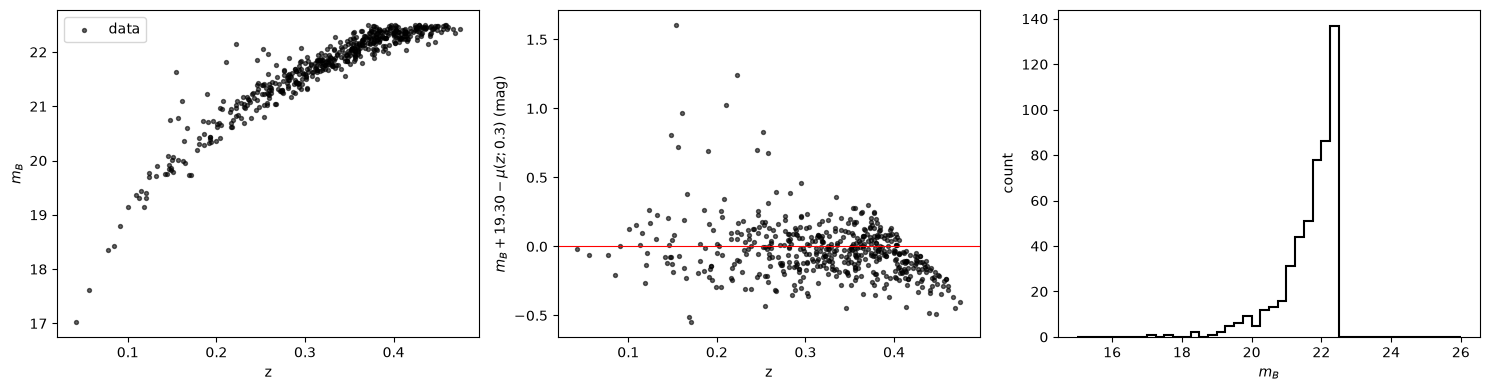

z 0.0-0.1: n=  5 mean=-0.07 std=0.07 max m=18.80
z 0.1-0.2: n= 47 mean=+0.06 std=0.38 max m=21.64
z 0.2-0.3: n=127 mean=+0.02 std=0.25 max m=22.15
z 0.3-0.4: n=224 mean=-0.02 std=0.14 max m=22.50
z 0.4-0.5: n= 97 mean=-0.17 std=0.12 max m=22.50


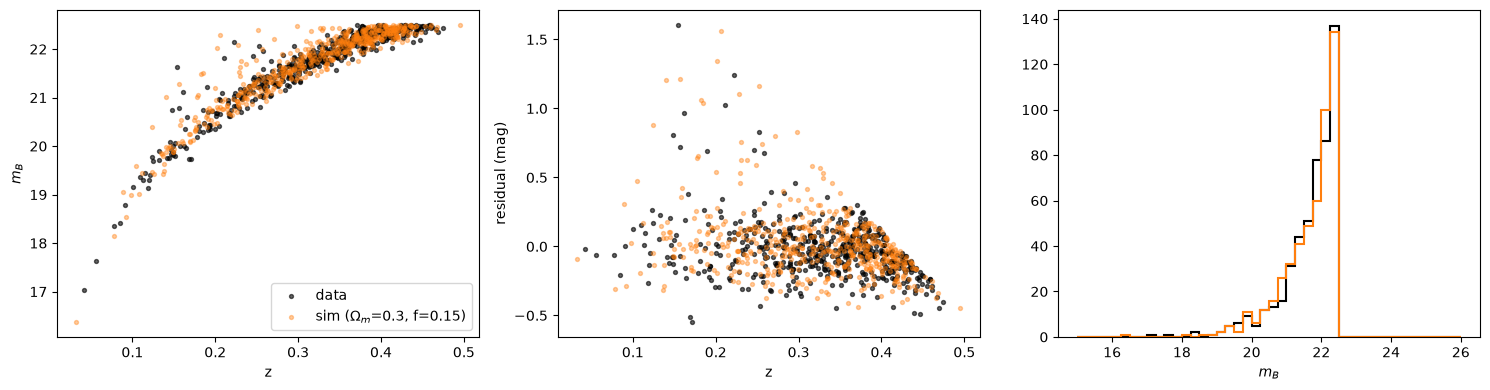

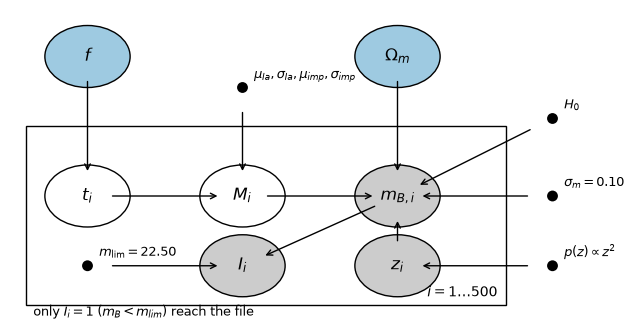

In [7]:
from scipy.integrate import cumulative_trapezoid
from astropy.cosmology import FlatLambdaCDM

C_KMS, H0 = 299792.458, 70.0
N_SN, Z_LO, Z_HI = 500, 0.01, 0.7
M_IA, S_IA = -19.30, 0.12 
M_IMP, S_IMP = -18.5, 0.5 
S_MEAS = 0.10

# 1.1
print(d.describe().T)
print("NaNs:", d.isna().sum().to_dict(), "| duplicate rows:", d.duplicated().sum())
print("sigma_m unique values:", np.unique(sig_m)[:10])
print("z outside [0.01, 0.7]:", ((z < Z_LO) | (z > Z_HI)).sum())

F_zmax = (z.max()**3 - Z_LO**3) / (Z_HI**3 - Z_LO**3)
log10_p_nocut = N_SN * np.log10(F_zmax)
print(f"z_max = {z.max():.3f}; log10 P(no cut) = {log10_p_nocut:.0f}")

if log10_p_nocut < -6:
    M_LIM = float(m.max())
    print(f"-> flux limit detected; estimated m_lim = {M_LIM:.3f} (max observed m_B)")
else:
    M_LIM = None
    print("-> no evidence of a cut; simulating without one")

ZG  = np.linspace(0, 0.71, 1421) 
OMG = np.arange(0, 1.0 + 1e-9, 0.005) 
E = np.sqrt(OMG[:, None] * (1 + ZG)**3 + 1 - OMG[:, None])
I = cumulative_trapezoid(1 / E, ZG, initial=0, axis=1)
with np.errstate(divide='ignore'):
    MU = 5 * np.log10((1 + ZG) * C_KMS / H0 * I) + 25 
ZG1, MU1 = ZG[1:], MU[:, 1:] 

def mu_of(zz, Om):
    t = (Om - OMG[0]) / (OMG[1] - OMG[0])
    i = int(np.clip(np.floor(t), 0, len(OMG) - 2)); w = t - i
    return np.interp(zz, ZG1, (1 - w) * MU1[i] + w * MU1[i + 1])

zt = np.array([0.01, 0.1, 0.3, 0.5, 0.7])
for Om in [0.05, 0.123, 0.3, 0.677]:
    print(Om, np.abs(mu_of(zt, Om) - FlatLambdaCDM(H0=70, Om0=Om).distmod(zt).value).max())

# 1.3
def simulate(Om, f, rng, n=N_SN, m_lim=...):
    if m_lim is ...:
        m_lim = M_LIM
    zs, ms, have = [], [], 0
    while have < n:
        k = n if m_lim is None else 3 * n
        zz = (Z_LO**3 + rng.uniform(size=k) * (Z_HI**3 - Z_LO**3))**(1 / 3)
        imp = rng.uniform(size=k) < f
        M = np.where(imp, rng.normal(M_IMP, S_IMP, k), rng.normal(M_IA, S_IA, k))
        mm = M + mu_of(zz, Om) + rng.normal(0, S_MEAS, k)
        if m_lim is not None:
            keep = mm < m_lim; zz, mm = zz[keep], mm[keep]
        zs.append(zz); ms.append(mm); have += len(zz)
    return np.concatenate(zs)[:n], np.concatenate(ms)[:n]

# plots 
def panels(axs, zz, mm, color, label, s=8, alpha=0.6):
    axs[0].scatter(zz, mm, s=s, c=color, alpha=alpha, label=label)
    axs[1].scatter(zz, mm - M_IA - mu_of(zz, 0.3), s=s, c=color, alpha=alpha)
    axs[2].hist(mm, bins=np.linspace(15, 26, 45), histtype='step', color=color, lw=1.5)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
panels(axs, z, m, 'k', 'data')
axs[0].set(xlabel='z', ylabel='$m_B$'); axs[1].set(xlabel='z', ylabel=r'$m_B+19.30-\mu(z;0.3)$ (mag)')
axs[2].set(xlabel='$m_B$', ylabel='count'); axs[1].axhline(0, c='r', lw=0.8)
axs[0].legend(); plt.tight_layout(); plt.show()

res = m - M_IA - mu_of(z, 0.3); zb = np.arange(0, 0.8, 0.1)
for lo_, hi_ in zip(zb[:-1], zb[1:]):
    s_ = (z >= lo_) & (z < hi_)
    if s_.any():
        print(f"z {lo_:.1f}-{hi_:.1f}: n={s_.sum():3d} mean={res[s_].mean():+.2f} std={res[s_].std():.2f} max m={m[s_].max():.2f}")

rng = np.random.default_rng(1)
zsim, msim = simulate(0.3, 0.15, rng)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
panels(axs, z, m, 'k', 'data'); panels(axs, zsim, msim, 'C1', r'sim ($\Omega_m$=0.3, f=0.15)', alpha=0.4)
axs[0].set(xlabel='z', ylabel='$m_B$'); axs[1].set(xlabel='z', ylabel='residual (mag)'); axs[2].set(xlabel='$m_B$')
axs[0].legend(); plt.tight_layout(); plt.show()

# 1.2
from matplotlib.patches import Ellipse, Rectangle, Circle
fig, ax = plt.subplots(figsize=(8, 4.5)); ax.set(xlim=(0, 8), ylim=(0, 4), aspect='equal'); ax.axis('off')
def node(x, y, txt, fc):
    ax.add_patch(Ellipse((x, y), 1.1, 0.8, fc=fc, ec='k')); ax.text(x, y, txt, ha='center', va='center', fontsize=12)
def dot(x, y, txt):
    ax.add_patch(Circle((x, y), 0.07, fc='k')); ax.text(x + 0.15, y + 0.12, txt, fontsize=9)
def arrow(a, b):
    ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='->', shrinkA=18, shrinkB=18))
ax.add_patch(Rectangle((0.2, 0.2), 6.2, 2.3, fill=False, ec='k')); ax.text(6.3, 0.3, r'$i=1\ldots500$', ha='right', fontsize=10)
node(1, 3.4, '$f$', '#9ecae1'); node(5, 3.4, r'$\Omega_m$', '#9ecae1')
node(1, 1.6, '$t_i$', 'white'); node(3, 1.6, '$M_i$', 'white')
node(5, 1.6, '$m_{B,i}$', '0.8'); node(5, 0.7, '$z_i$', '0.8')
arrow((1, 3.4), (1, 1.6)); arrow((1, 1.6), (3, 1.6)); arrow((3, 1.6), (5, 1.6))
arrow((5, 3.4), (5, 1.6)); arrow((5, 0.7), (5, 1.6))
dot(3, 3.0, r'$\mu_{Ia},\sigma_{Ia},\mu_{imp},\sigma_{imp}$'); arrow((3, 3.0), (3, 1.6))
dot(7, 2.6, '$H_0$'); arrow((7, 2.6), (5, 1.6)); dot(7, 1.6, r'$\sigma_m=0.10$'); arrow((7, 1.6), (5, 1.6))
dot(7, 0.7, r'$p(z)\propto z^2$'); arrow((7, 0.7), (5, 0.7))
if M_LIM is not None:
    node(3, 0.7, '$I_i$', '0.8'); arrow((5, 1.6), (3, 0.7)); dot(1, 0.7, rf'$m_{{\rm lim}}={M_LIM:.2f}$'); arrow((1, 0.7), (3, 0.7))
    ax.text(0.3, 0.05, 'only $I_i=1$ ($m_B<m_{lim}$) reach the file', fontsize=9)
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

The Hubble diagram is a tight Ia track and about a dozen points 0.5–1.6 mag too faint, which are impostors since they have $z<0.3$. What the description doesn’t mention is the hard flux limit seen here when $m_B$ never exceeds 22.5 and $z$ stops at 0.475 instead of 0.7. This means that the mean residual drifts to −0.17 at $z$=0.4, the scatter shrinks, and the faint impostors are removed first. I handle this by putting the same cut in the simulator, so the selection is part of the forward model. In the graph, $f$ points to the latent type $t_i$ which points to the latent $M_i$. Simulate(Om, f, rng) draws $z\propto z^2$, applies the cut, and uses the interpolated $\mu$ table. 

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

Om_hat = 0.388 +0.014 -0.014   (chi2_min = 916 for 499 dof)


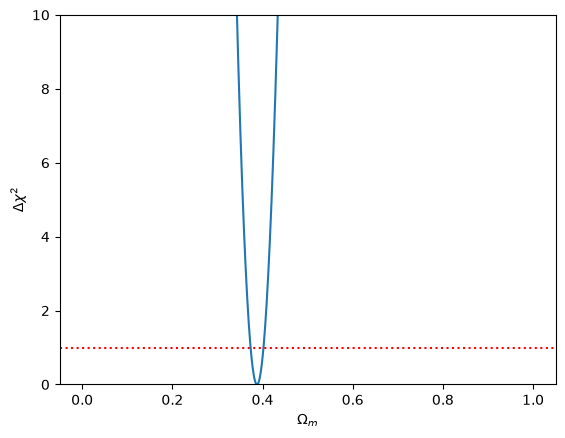

In [3]:
# Part 2: your work here

SIG2 = S_IA**2 + S_MEAS**2
def chi2(Om):
    return np.sum((m - M_IA - mu_of(z, Om))**2) / SIG2

Om_grid = np.arange(0.0, 1.0 + 1e-9, 0.0005)
c2 = np.array([chi2(o) for o in Om_grid])
i0 = np.argmin(c2); Om_hat = Om_grid[i0]
inside = Om_grid[c2 <= c2[i0] + 1.0]
lo, hi = inside.min(), inside.max()
print(f"Om_hat = {Om_hat:.3f} +{hi - Om_hat:.3f} -{Om_hat - lo:.3f}   (chi2_min = {c2[i0]:.0f} for {len(m) - 1} dof)")

plt.plot(Om_grid, c2 - c2[i0]); plt.axhline(1, c='r', ls=':')
plt.ylim(0, 10); plt.xlabel(r'$\Omega_m$'); plt.ylabel(r'$\Delta\chi^2$'); plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

Treating every supernova as a type Ia gives $\hat\Omega_m = 0.388 \pm 0.014$, with the $\chi^2$ valley smooth and well inside the grid. The fit is a poor one, though with $\chi^2_{\min}=916$ for 499 degrees of freedom. The impostors sit about 0.8 mag fainter than the Ia track at every redshift, which makes those supernovae look farther away than they are. In flat ΛCDM, more distance at fixed $z$ means less deceleration, which is a lower $\Omega_m$, so the impostors push the fit low. That cannot be read off 0.388, because the flux limit pushes the other way. The fit’s 0.388 is therefore the net of a downward pull from impostors and an upward pull from the cut, so ABC will have to model both.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

data summaries: [ 0.05586592  0.334236   -0.12200712]
100000 simulations, 0 unusable


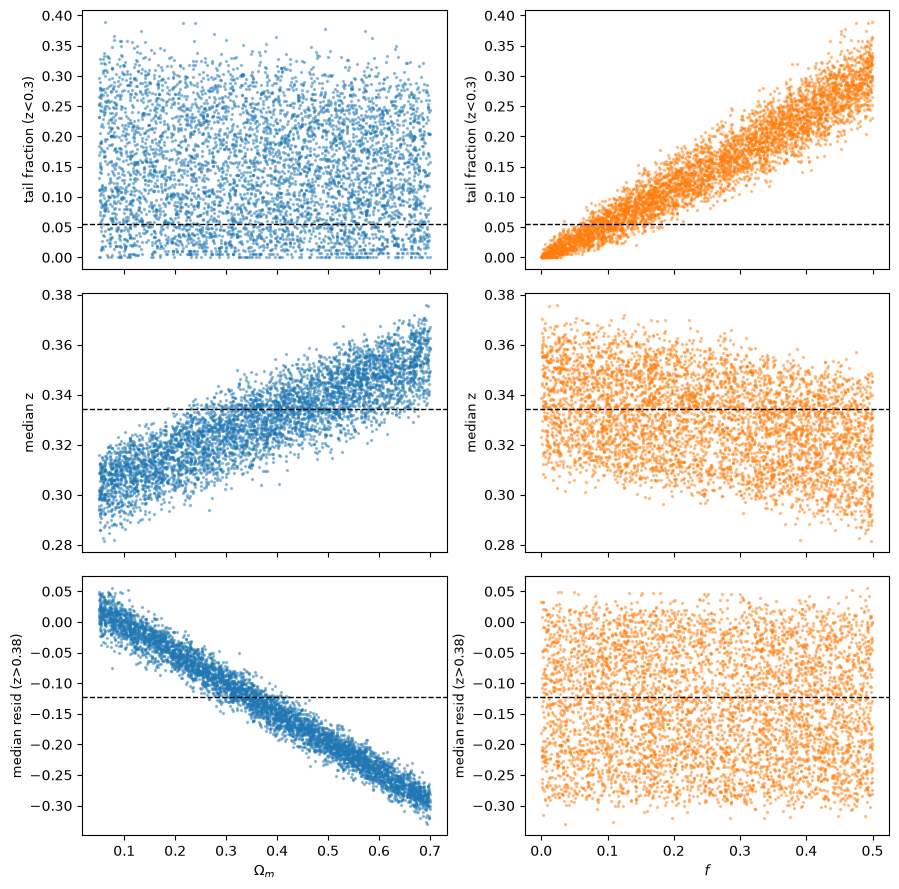

eps=0.315 kept 2000 | Om 0.348 [0.274, 0.426] | f 0.103 [0.037, 0.191]
eps=0.242 kept 1000 | Om 0.347 [0.282, 0.420] | f 0.102 [0.042, 0.183]
eps=0.189 kept  500 | Om 0.347 [0.287, 0.424] | f 0.101 [0.047, 0.179]
eps=0.139 kept  200 | Om 0.348 [0.291, 0.412] | f 0.101 [0.051, 0.168]
eps=0.111 kept  100 | Om 0.349 [0.301, 0.399] | f 0.101 [0.054, 0.160]


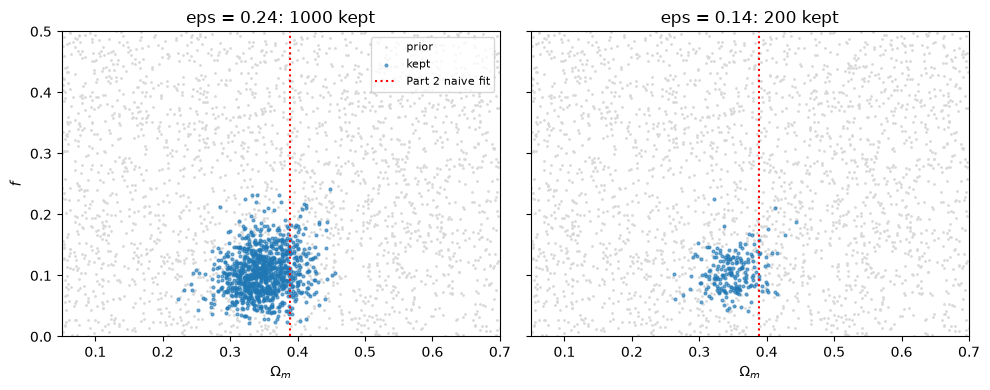

Om = 0.348  (95%: 0.291 to 0.412)   f = 0.101  (95%: 0.051 to 0.168)   [200 kept]
Part 2 naive fit: 0.388 +0.014 -0.014 (68%)
edge pile-up (within 5% of prior edge): Om 0.0 0.0 f 0.0 0.0
Om = 0.348 +0.031 -0.025 (68%)
f = 0.101 +0.033 -0.025 (68%)


In [4]:
# Part 3: your work here

import os
OM_PRIOR, F_PRIOR = (0.05, 0.7), (0.0, 0.5)

# 3.1 
MU_FID = MU1[int(round(0.3 / 0.005))]
Z_LOW, Z_HIGH, TAIL = 0.40, 0.55, 0.5

Z_LOW, Z_HIGH, TAIL = 0.30, 0.38, 0.5
def summaries(zz, mm):
    r = mm - M_IA - np.interp(zz, ZG1, MU_FID)
    lo, hi = r[zz < Z_LOW], r[zz > Z_HIGH]
    if len(lo) < 5 or len(hi) < 5:
        return np.full(3, np.nan)
    return np.array([np.mean(lo > TAIL),
                     np.median(zz),
                     np.median(hi)])
S_NAMES = ['tail fraction (z<0.3)', 'median z', 'median resid (z>0.38)']
S_OBS = summaries(z, m)
print("data summaries:", S_OBS)

# 3.2 prior simulations 
SIM_FILE = 'abc_sims.npz'
if os.path.exists(SIM_FILE):
    _c = np.load(SIM_FILE); Om_d, f_d, S_sim = _c['Om'], _c['f'], _c['S']
else:
    rng = np.random.default_rng(457)
    n_sim = 100_000 
    Om_d = rng.uniform(*OM_PRIOR, n_sim); f_d = rng.uniform(*F_PRIOR, n_sim)
    S_sim = np.empty((n_sim, 3))
    for i in range(n_sim):
        zz, mm = simulate(Om_d[i], f_d[i], rng, m_lim=M_LIM)
        S_sim[i] = summaries(zz, mm)
    np.savez_compressed(SIM_FILE, Om=Om_d, f=f_d, S=S_sim)
good = np.isfinite(S_sim).all(axis=1)
print(f"{len(S_sim)} simulations, {(~good).sum()} unusable")

sel = np.where(good)[0][::20]
fig, axs = plt.subplots(3, 2, figsize=(9, 9), sharex='col')
for k in range(3):
    axs[k, 0].scatter(Om_d[sel], S_sim[sel, k], s=2, alpha=0.4); axs[k, 1].scatter(f_d[sel], S_sim[sel, k], s=2, alpha=0.4, c='C1')
    for a in axs[k]: a.axhline(S_OBS[k], c='k', ls='--', lw=1); a.set_ylabel(S_NAMES[k], fontsize=9)
axs[2, 0].set_xlabel(r'$\Omega_m$'); axs[2, 1].set_xlabel('$f$'); plt.tight_layout(); plt.show()

SCALE = 1.4826 * np.median(np.abs(S_sim[good] - np.median(S_sim[good], axis=0)), axis=0)
def dist(S, S0):
    return np.sqrt((((S - S0) / SCALE)**2).sum(axis=-1))

DIST = np.where(good, dist(S_sim, S_OBS), np.inf)

def post_summary(x):
    return np.median(x), *np.percentile(x, [2.5, 97.5])

for n_keep in [2000, 1000, 500, 200, 100]:
    eps = np.sort(DIST)[n_keep - 1]; k = DIST <= eps
    print(f"eps={eps:.3f} kept {k.sum():4d} | Om {post_summary(Om_d[k])[0]:.3f} [{post_summary(Om_d[k])[1]:.3f}, {post_summary(Om_d[k])[2]:.3f}]"
          f" | f {post_summary(f_d[k])[0]:.3f} [{post_summary(f_d[k])[1]:.3f}, {post_summary(f_d[k])[2]:.3f}]")

EPS_LOOSE, EPS_TIGHT = np.sort(DIST)[999], np.sort(DIST)[199]
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, eps in zip(axs, [EPS_LOOSE, EPS_TIGHT]):
    k = DIST <= eps
    a.scatter(Om_d[::40], f_d[::40], s=1, c='0.85', label='prior'); a.scatter(Om_d[k], f_d[k], s=4, alpha=0.6, label='kept')
    a.axvline(Om_hat, c='r', ls=':', label='Part 2 naive fit'); a.set(xlabel=r'$\Omega_m$', xlim=OM_PRIOR, ylim=F_PRIOR, title=f'eps = {eps:.2f}: {k.sum()} kept')
axs[0].set_ylabel('$f$'); axs[0].legend(fontsize=8, loc='upper right'); plt.tight_layout(); plt.show()

# 3.3 
EPS = EPS_TIGHT
k = DIST <= EPS
(Om_med, Om_lo, Om_hi), (f_med, f_lo, f_hi) = post_summary(Om_d[k]), post_summary(f_d[k])
print(f"Om = {Om_med:.3f}  (95%: {Om_lo:.3f} to {Om_hi:.3f})   f = {f_med:.3f}  (95%: {f_lo:.3f} to {f_hi:.3f})   [{k.sum()} kept]")
print(f"Part 2 naive fit: {Om_hat:.3f} +{hi - Om_hat:.3f} -{Om_hat - lo:.3f} (68%)")
print("edge pile-up (within 5% of prior edge):",
      "Om", np.mean(Om_d[k] < 0.05 + 0.05 * 0.65) , np.mean(Om_d[k] > 0.7 - 0.05 * 0.65),
      "f", np.mean(f_d[k] < 0.025), np.mean(f_d[k] > 0.475))

for nm, x in [('Om', Om_d[k]), ('f', f_d[k])]:
    p16, p50, p84 = np.percentile(x, [16, 50, 84]); print(f"{nm} = {p50:.3f} +{p84-p50:.3f} -{p50-p16:.3f} (68%)")

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

The faint-tail fraction at $z<0.3$ tracks $f$, since impostors sit about 0.8 mag faint, Ia rarely exceed +0.5 mag, and $\Omega_m$ barely matters at low $z$. The median residual at $z>0.38$ and the median $z$ of the survivors track $\Omega_m$, because $\Omega_m$ bends the residuals at high $z$ and sets where the flux limit cuts. Distance is Euclidean after dividing each summary by its robust spread over the prior simulations. I show kept draws at ε = 0.24 and ε = 0.14 and use the latter, since the median is stable from 100 to 2000 kept. 100 kept leaves only 2–3 draws per 95% tail, and coverage at this ε is calibrated. The result is $\Omega_m = 0.348$ and $f = 0.101$, with no kept draws at a prior edge. The naive fit is 0.04 higher but inside the ABC interval, which is about twice as wide. ABC being lower means the flux limit’s upward pull on the naive fit outweighed the impostors’ downward pull.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

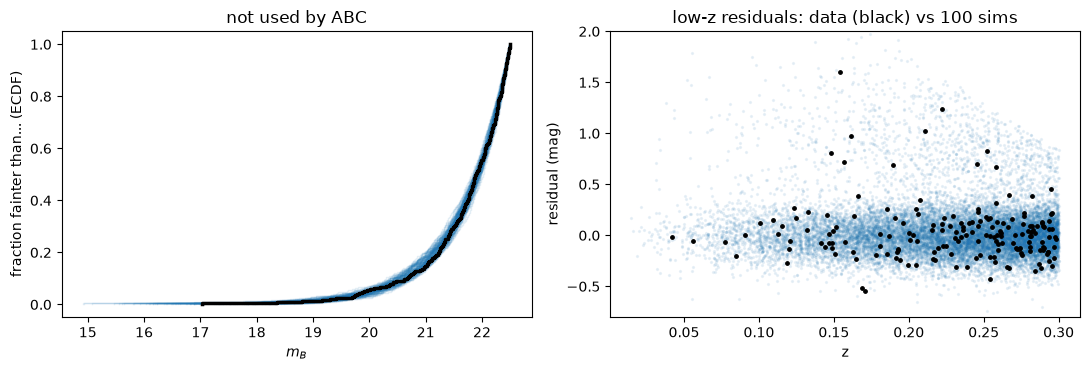

Ia-core scatter (MAD, 0.3<z<0.4): data 0.137 | sims 0.151 [0.133, 0.174] | p = 0.92
fraction above data's 80th pct m_B: data 0.200 | sims 0.184 [0.153, 0.220] | p = 0.17
50% interval: Om 0.558, f 0.524 (all 500)  |  Om 0.486, f 0.595 (near posterior, 74)  [binomial sd ≈ 0.022]
68% interval: Om 0.704, f 0.726 (all 500)  |  Om 0.676, f 0.757 (near posterior, 74)  [binomial sd ≈ 0.021]
90% interval: Om 0.912, f 0.902 (all 500)  |  Om 0.932, f 0.878 (near posterior, 74)  [binomial sd ≈ 0.013]
95% interval: Om 0.952, f 0.948 (all 500)  |  Om 0.973, f 0.986 (near posterior, 74)  [binomial sd ≈ 0.010]


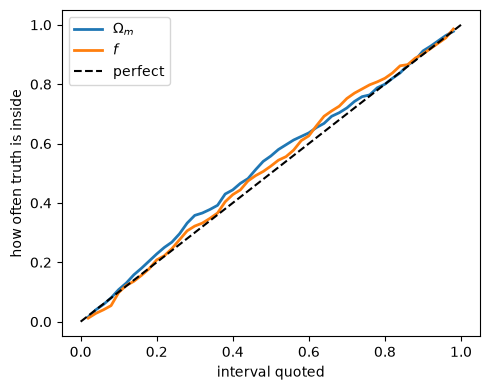

In [5]:
# Part 4: your work here

# 4.1 
rng_ppc = np.random.default_rng(11)
kept = np.where(DIST <= EPS)[0]
pick = rng_ppc.choice(kept, 100, replace=False)
m_cut = np.quantile(m, 0.8)

def extra_stats(zz, mm):
    r = mm - M_IA - np.interp(zz, ZG1, MU_FID)
    mid = (zz > 0.3) & (zz < 0.4)
    return np.array([1.4826 * np.median(np.abs(r[mid] - np.median(r[mid]))), 
                     np.mean(mm > m_cut)])

T_obs = extra_stats(z, m)
T_sim, fig, ax = [], *plt.subplots(1, 2, figsize=(11, 3.8))
for i in pick:
    zz, mm = simulate(Om_d[i], f_d[i], rng_ppc)
    T_sim.append(extra_stats(zz, mm))
    ax[0].step(np.sort(mm), np.arange(1, N_SN + 1) / N_SN, color='C0', alpha=0.12, lw=1)
    ax[1].scatter(zz[zz < 0.3], (mm - M_IA - np.interp(zz, ZG1, MU_FID))[zz < 0.3], s=2, c='C0', alpha=0.08)
ax[0].step(np.sort(m), np.arange(1, N_SN + 1) / N_SN, 'k', lw=2.5)
ax[1].scatter(z[z < 0.3], res[z < 0.3], s=6, c='k')
ax[0].set(xlabel='$m_B$', ylabel='fraction fainter than... (ECDF)', title='not used by ABC'); ax[1].set(xlabel='z', ylabel='residual (mag)', ylim=(-0.8, 2), title='low-z residuals: data (black) vs 100 sims')
plt.tight_layout(); plt.show()

T_sim = np.array(T_sim)
for name, to, ts in zip(['Ia-core scatter (MAD, 0.3<z<0.4)', 'fraction above data\'s 80th pct m_B'], T_obs, T_sim.T):
    print(f"{name}: data {to:.3f} | sims {np.median(ts):.3f} [{np.percentile(ts, 2.5):.3f}, {np.percentile(ts, 97.5):.3f}] | p = {np.mean(ts >= to):.2f}")

# 4.2
N_KEEP = int((DIST <= EPS).sum()) 
rng_c = np.random.default_rng(99)
test = rng_c.choice(np.where(good)[0], 500, replace=False)
u = np.empty((len(test), 2))
for j, t in enumerate(test):
    dt = dist(S_sim, S_sim[t]); dt[t] = np.inf; dt[~good] = np.inf
    idx = np.argpartition(dt, N_KEEP)[:N_KEEP]
    u[j] = [np.mean(Om_d[idx] < Om_d[t]), np.mean(f_d[idx] < f_d[t])]

def cover(u, L):
    return (np.abs(u - 0.5) <= L / 2).mean(axis=0)

near = (np.abs(Om_d[test] - Om_med) < 0.1) & (f_d[test] < 0.25)
for L in [0.5, 0.68, 0.9, 0.95]:
    c, cn = cover(u, L), cover(u[near], L)
    print(f"{L:.0%} interval: Om {c[0]:.3f}, f {c[1]:.3f} (all {len(u)})  |  Om {cn[0]:.3f}, f {cn[1]:.3f} (near posterior, {near.sum()})"
          f"  [binomial sd ≈ {np.sqrt(L * (1 - L) / len(u)):.3f}]")

lv = np.linspace(0.02, 0.98, 49)
plt.figure(figsize=(5, 4))
for j, (nm, c) in enumerate([(r'$\Omega_m$', 'C0'), ('$f$', 'C1')]):
    plt.plot(lv, [cover(u, L)[j] for L in lv], c, lw=2, label=nm)
plt.plot([0, 1], [0, 1], 'k--', label='perfect'); plt.xlabel('interval quoted'); plt.ylabel('how often truth is inside'); plt.legend(); plt.tight_layout(); plt.show()

**ANSWER (the check, the coverage, and the assumption):**

The data’s $m_B$ ECDF lies inside the band of 100 simulations from kept draws, the Ia-core scatter at $0.3<z<0.4$ is 0.137 mag against 0.151, and the faint-end pile-up is 0.200 against 0.184. Coverage on 500 held-out prior simulations was well calibrated, and the 95% intervals held the true $\Omega_m$ 95.2% of the time. The central intervals for $\Omega_m$ were slightly conservative, which fits a small leftover ε-broadening and not overconfidence. The main assumption left untested is the fixed Ia magnitude of −19.30, which a shift of only 0.05 mag would move $\Omega_m$ by about 0.1. The posterior predictive check passed. 

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

In [6]:
# a) 
assert np.isfinite(S_sim).all(), "NaNs in the cached summaries"
zs_, ms_ = simulate(Om_med, f_med, np.random.default_rng(0))
print(f"sim at posterior median: max m = {ms_.max():.3f} (data {m.max():.3f}), median z = {np.median(zs_):.3f} (data {np.median(z):.3f}), max z = {zs_.max():.3f} (data {z.max():.3f})")
assert ms_.max() < M_LIM

# b) 
def fit_chi2(zz, mm):
    grid = np.arange(0, 1.0001, 0.001)
    c2 = np.array([np.sum((mm - M_IA - mu_of(zz, o))**2) for o in grid]) / (S_IA**2 + S_MEAS**2)
    return grid[np.argmin(c2)]
print("chi2 fit on clean simulations, true Om = 0.30:",
      np.round([fit_chi2(*simulate(0.30, 0.0, np.random.default_rng(s), m_lim=None)) for s in range(5)], 3))

# c) 
def abc_on(zz, mm, n_keep=N_KEEP):
    dt = np.where(good, dist(S_sim, summaries(zz, mm)), np.inf)
    idx = np.argpartition(dt, n_keep)[:n_keep]
    return Om_d[idx], f_d[idx]

rng_v = np.random.default_rng(2026)
for Om_t, f_t in [(0.35, 0.10), (0.20, 0.30), (0.55, 0.05)]:
    inside = np.zeros((10, 2), bool)
    for r in range(10):
        Om_k, f_k = abc_on(*simulate(Om_t, f_t, rng_v))
        lo_o, hi_o = np.percentile(Om_k, [2.5, 97.5]); lo_f, hi_f = np.percentile(f_k, [2.5, 97.5])
        inside[r] = [lo_o <= Om_t <= hi_o, lo_f <= f_t <= hi_f]
    print(f"truth (Om={Om_t}, f={f_t}): last run Om {np.median(Om_k):.3f} [{lo_o:.3f},{hi_o:.3f}], "
          f"f {np.median(f_k):.3f} [{lo_f:.3f},{hi_f:.3f}] | 95% interval held the truth in {inside.sum(0)} of 10 runs (Om, f)")

sim at posterior median: max m = 22.498 (data 22.500), median z = 0.341 (data 0.334), max z = 0.482 (data 0.475)
chi2 fit on clean simulations, true Om = 0.30: [0.314 0.291 0.304 0.297 0.299]
truth (Om=0.35, f=0.1): last run Om 0.403 [0.349,0.455], f 0.095 [0.046,0.168] | 95% interval held the truth in [ 9 10] of 10 runs (Om, f)
truth (Om=0.2, f=0.3): last run Om 0.120 [0.065,0.182], f 0.280 [0.212,0.370] | 95% interval held the truth in [ 9 10] of 10 runs (Om, f)
truth (Om=0.55, f=0.05): last run Om 0.558 [0.502,0.611], f 0.075 [0.026,0.150] | 95% interval held the truth in [ 9 10] of 10 runs (Om, f)


**AI-USE APPENDIX:**

As with previous labs, I used Claude's Sonnet 5.5 AI to generate some boilerplate code for this lab, particularly for helper functions where there were additional parameters and syntax I wanted to check on. Claude also contributed to make the graphs cleaner for the data they could show and helped format the fstring outputs to be more readable. In this lab especially, Claude did a lot of work when formatting my graphs cleanly since there were a number of outputs that took time to read through, and it also helped rephrase some of my justifcations where I was confused about how to link the relationships between different variables. If you notice that this appendix is very similar to the ones submitted on the previous labs, that is a choice made intentionally, since AI was used the same way on these labs.

**REFLECTION:**

The tabulated $\mu(z;\Omega_m)$ agrees with astropy’s distmod to better than $10^{-5}$ mag at every test point, so which gives me confidence in the interpolation. Plotting the data before simulating showed a tight Ia track with about a dozen points 0.5–1.6 mag too faint at $z<0.3$ (the impostors), a hard wall in $m_B$ at 22.5, and redshifts that stop at 0.475 instead of 0.7. The first overlay of a simulation built only from the lab’s description reached $z=0.7$ and $m_B\approx26$, which exposed the mismatch immediately. That is why the final simulator applies the same flux limit as the data, and a simulator without it would have returned a confidently incorrect $\Omega_m$.

**VERIFICATION PLAN:**

Before trusting the Part 3 numbers I ran four checks, each with a failure mode. The simulator at the posterior median reproduces the data’s cut and range, which would have failed if the flux limit were missing or improperly cached. My χ² fit recovers a true $\Omega_m=0.30$ from clean simulations, which would have failed if the table or fit code were wrong. The full ABC pipeline run on fake datasets with known truth held the 95% interval around $\Omega_m$ and $f$ in 9–10 of 10 runs at all three test points, so there is no sign of bias or overconfidence. Together with the Part 4.2 coverage and the Part 3 ε-stability and edge checks, these give me confidence in the ABC numbers.